# Unsupervised learning

### Library importing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score,davies_bouldin_score
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.datasets import fetch_california_housing, load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, accuracy_score

%matplotlib inline

### K-Means Clustering

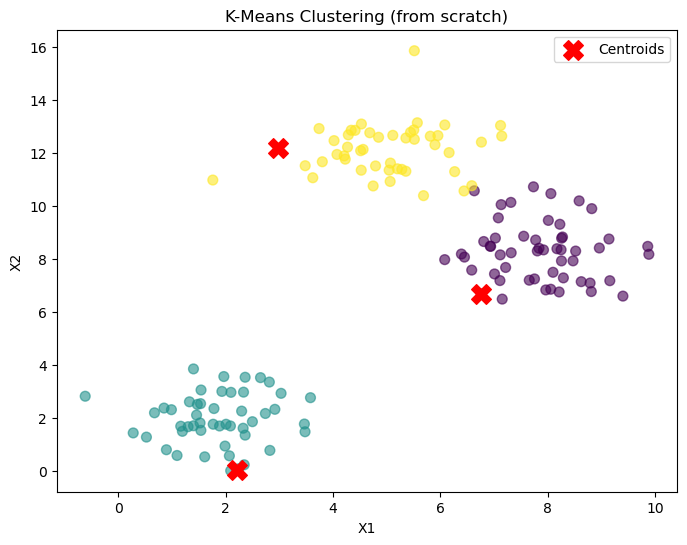

In [4]:
# -------------------------------
# Step 1: Generate sample dataset
# -------------------------------

np.random.seed(42)
# Create two clusters around (2,2) and (8,8)
cluster_1 = np.random.randn(50, 2) + np.array([2, 2])
cluster_2 = np.random.randn(50, 2) + np.array([8, 8])
cluster_3 = np.random.randn(50, 2) + np.array([5, 12])
# Combine into one dataset
X = np.vstack((cluster_1, cluster_2, cluster_3))
df = pd.DataFrame(X, columns=["X1", "X2"])

# -------------------------------
# Step 2: K-Means Implementation
# -------------------------------

def kmeans(X, K, max_iters=100):
 # Randomly initialize centroids
 np.random.seed(42)
 centroids = X[np.random.choice(range(X.shape[0]), K,
replace=False)]

 for _ in range(max_iters):
 # Assignment step
  distances = np.sqrt(((X - centroids[:,
  np.newaxis])**2).sum(axis=2))
  labels = np.argmin(distances, axis=0)

 # Update step
  new_centroids = np.array([X[labels==k].mean(axis=0) for k in range(K)])

 # Convergence check
  if np.all(centroids == new_centroids):
   break
   centroids = new_centroids
 return centroids, labels

# Run K-Means with K=3
final_centroids, cluster_labels = kmeans(X, K=3)

# -------------------------------
# Step 3: Visualization
# -------------------------------
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", s=50, alpha=0.6)
plt.scatter(final_centroids[:,0], final_centroids[:,1], c="red", marker="X", s=200,
label="Centroids")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("K-Means Clustering (from scratch)")
plt.legend()
plt.show()

# Agglomerative Hierarchical Clustering

Dataset:
     X1  X2
0  1.0   1
1  1.5   2
2  5.0   5
3  6.0   6

Pairwise Distance Matrix:
           0         1         2         3
0  0.000000  1.118034  5.656854  7.071068
1  1.118034  0.000000  4.609772  6.020797
2  5.656854  4.609772  0.000000  1.414214
3  7.071068  6.020797  1.414214  0.000000

Linkage Matrix:
 [[0.         1.         1.11803399 2.        ]
 [2.         3.         1.41421356 2.        ]
 [4.         5.         8.25378701 4.        ]]


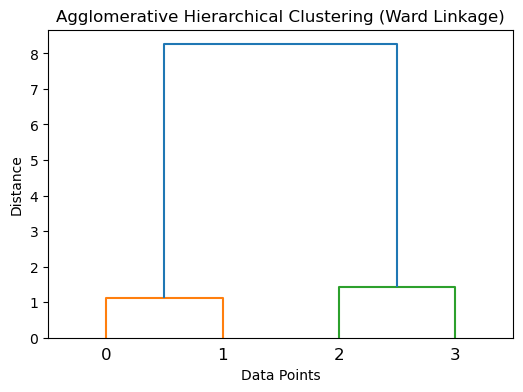

In [5]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt
# Sample dataset (4 points in 2D)
data = pd.DataFrame({'X1': [1, 1.5, 5, 6],'X2': [1, 2, 5, 6]})

print("Dataset:\n", data)
# Step 1: Compute pairwise distances
dist_matrix = squareform(pdist(data, metric='euclidean'))
print("\nPairwise Distance Matrix:\n", pd.DataFrame(dist_matrix, index=data.index,
columns=data.index))
# Step 2: Perform hierarchical clustering (Agglomerative with 'ward')
Z = linkage(data, method='ward')
print("\nLinkage Matrix:\n", Z)
# Step 3: Plot dendrogram
plt.figure(figsize=(6,4))
dendrogram(Z, labels=data.index.tolist())
plt.title("Agglomerative Hierarchical Clustering (Ward Linkage)")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

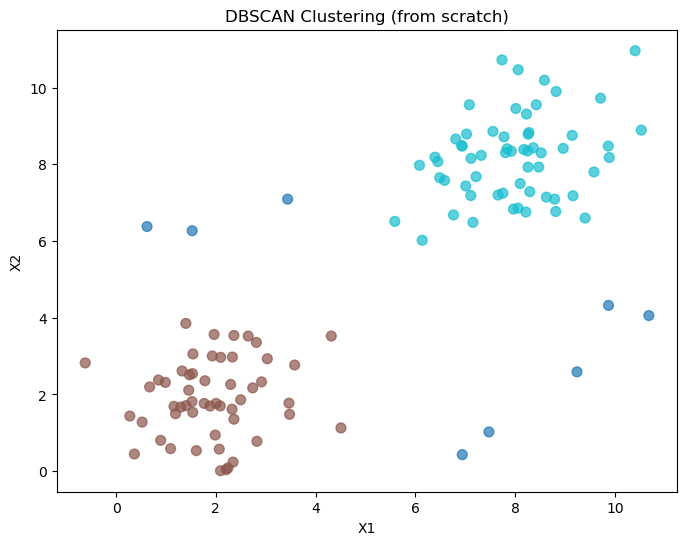

In [6]:

# -------------------------------
# Step 1: Generate synthetic dataset
# -------------------------------
np.random.seed(42)
cluster_1 = np.random.randn(50, 2) + np.array([2, 2])
cluster_2 = np.random.randn(50, 2) + np.array([8, 8])
noise = np.random.uniform(low=0, high=12, size=(20, 2))

X = np.vstack((cluster_1, cluster_2, noise))
df = pd.DataFrame(X, columns=["X1", "X2"])

# -------------------------------
# Step 2: DBSCAN implementation
# -------------------------------
def dbscan(X, eps, min_pts):
    n = X.shape[0]
    labels = np.full(n, -1)  # -1 means noise
    visited = np.zeros(n, dtype=bool)
    cluster_id = 0

    def region_query(p):
        distances = np.sqrt(np.sum((X - X[p])**2, axis=1))
        return np.where(distances <= eps)[0]

    for p in range(n):
        if visited[p]:
            continue
        visited[p] = True
        neighbors = region_query(p)
        if len(neighbors) < min_pts:
            labels[p] = -1  # noise
        else:
            labels[p] = cluster_id
            seeds = list(neighbors)
            while seeds:
                q = seeds.pop()
                if not visited[q]:
                    visited[q] = True
                    q_neighbors = region_query(q)
                    if len(q_neighbors) >= min_pts:
                        seeds.extend(q_neighbors)
                if labels[q] == -1:
                    labels[q] = cluster_id
            cluster_id += 1
    return labels

# Run DBSCAN
labels = dbscan(X, eps=1.5, min_pts=5)

# -------------------------------
# Step 3: Visualization
# -------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=50, alpha=0.7)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("DBSCAN Clustering (from scratch)")
plt.show()

### PCA

In [7]:

# Sample data
data = pd.DataFrame({"Feature1": [2.5, 0.5, 2.2, 1.9, 3.1, 2.3, 2, 1, 1.5, 1.1],"Feature2": [2.4, 0.7, 2.9, 2.2, 3, 2.7, 1.6, 1.1, 1.6, 0.9]})
# Step 1: Standardize
X = data - data.mean()
# Step 2: Covariance Matrix
cov_matrix = np.cov(X.T)
# Step 3: Eigen Decomposition
eig_vals, eig_vecs = np.linalg.eig(cov_matrix)

idx = np.argsort(eig_vals)[::-1]
eig_vecs = eig_vecs[:, idx]
# Step 5: Projection onto first principal component
X_pca = np.dot(X, eig_vecs[:, :1])
print("Projected Data:\n", X_pca)

Projected Data:
 [[-0.82797019]
 [ 1.77758033]
 [-0.99219749]
 [-0.27421042]
 [-1.67580142]
 [-0.9129491 ]
 [ 0.09910944]
 [ 1.14457216]
 [ 0.43804614]
 [ 1.22382056]]


In [11]:
#Evaluating Clustering

# Generate synthetic data
X, _= make_blobs(n_samples=500,centers=4, random_state=42)

# Fit KMeans
kmeans = KMeans(n_clusters=4,random_state=42)
labels = kmeans.fit_predict(X)

sil_score = silhouette_score(X,labels)
ch_score = calinski_harabasz_score(X, labels)
db_score =davies_bouldin_score(X, labels)
print("Silhouette Score:", sil_score)
print("Calinski-Harabasz Index:",ch_score)
print("Davies-Bouldin Index:", db_score)



Silhouette Score: 0.7911042588289479
Calinski-Harabasz Index: 5742.035759058726
Davies-Bouldin Index: 0.29385150725841225


C:\Users\uri2350247\AppData\Local\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


#### Cross Validation

In [17]:
X, y= load_iris(return_X_y=True)
model =LogisticRegression(max_iter=200)

kf=KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=kf)
print("K-Fold CV Scores:", scores)
print("Mean Accuracy:", scores.mean())

# Stratified k-Fold CV
skf=StratifiedKFold(n_splits=5, shuffle=True,random_state=42)
scores_strat = cross_val_score(model, X,y,cv=skf)
print("Stratified K-Fold Mean Accuracy:",scores_strat.mean())

K-Fold CV Scores: [1.         1.         0.93333333 0.96666667 0.96666667]
Mean Accuracy: 0.9733333333333334
Stratified K-Fold Mean Accuracy: 0.9666666666666668


# Linear Regression with Regularization

In [2]:

X, y= fetch_california_housing(return_X_y=True)
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=0.2,random_state=42)
# Ridge
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
print("Ridge MSE:", mean_squared_error(y_test, ridge.predict(X_test)))

# Lasso
lasso= Lasso(alpha=0.1)

lasso.fit(X_train, y_train)
print("Lasso MSE:", mean_squared_error(y_test, lasso.predict(X_test)))

# Elastic Net
enet =ElasticNet(alpha=0.1, l1_ratio=0.5)
enet.fit(X_train, y_train)
print("Elastic Net MSE:", mean_squared_error(y_test, enet.predict(X_test)))

# --Classification with Regularization-----
    
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)

# Logistic Regression with L2 (default)
log_reg_l2 = LogisticRegression(penalty="l2", max_iter=200)
log_reg_l2.fit(X_train, y_train)
print("Logistic Regression (L2) Accuracy:", accuracy_score(y_test, log_reg_l2.predict(X_test)))

#Logistic Regression with L1
log_reg_l1 = LogisticRegression(penalty="l1", solver="liblinear", max_iter=200)
log_reg_l1.fit(X_train, y_train)
print("Logistic Regression (L1) Accuracy:", accuracy_score(y_test, log_reg_l1.predict(X_test)))

Ridge MSE: 0.5558034669932195
Lasso MSE: 0.6135115198058131
Elastic Net MSE: 0.5730994198028209
Logistic Regression (L2) Accuracy: 1.0
Logistic Regression (L1) Accuracy: 1.0
